# E4 — Reach sweep

`e4_reach.py`. A slow line outward with a dither, so inertial force is present all along. Expected: M4 (its
mass tuned at the start of the line) is right there and wrong further out; M5 follows the arm's Λ.

**Design `zdither` (2026-10-26):** x 0.30 → 0.68 m at z = 0.15 m (held Λ along z ~16 → ~7 kg), dither 3 cm
along z at 0.7 Hz, below the proxy's coupling resonance (1.3–1.9 Hz along the line), 1 cm/s along the line.

**The masses are phase-separated at the dither frequency** (`exp_metrics.e4`, `mass_by_s`): the in-phase part
of force over position, $-\mathrm{Re}(F/x)/\omega^2$, is a mass; friction, in phase with the velocity, drops out.
`m_robot` is the arm's (robot side), `m_felt` what the method renders (on the proxy's motion), `m_err` the mass
the operator was not shown ($e_F$ on the proxy's motion), `m_model` RIM's $n^\top\Lambda n$.

In [3]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e4")]
RECOMPUTE = True  # recompute the metrics (runs analysed before mass_by_s existed lack it)
DESIGN = "zdither"  # the runs' label: "zdither" (current design), "" (the first design: x at z = 0.25 m, 1.5 Hz)

In [4]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX: the GPU stays free for fr3_teleop's IK
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
%load_ext autoreload
%autoreload 2
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e4 if RECOMPUTE else None)
df = df[df.label.fillna("") == DESIGN].reset_index(drop=True)
print(f"{len(df)} runs, design {DESIGN!r}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
4 runs, design 'zdither'


## Run checks

In [5]:
from runs import load_run

loaded = {r: load_run(r) for r in df.dir}
res = {r: exp_metrics.e4(loaded[r]) for r in df.dir}
df["stop_reason"] = [loaded[r]["meta"].get("stop_reason") for r in df.dir]
df["proxy_mass"] = [loaded[r]["meta"]["args"].get("proxy_mass") for r in df.dir]
df["dither"] = [
    f"{loaded[r]['meta']['script']['dither_amplitude'] * 100:g} cm at {loaded[r]['meta']['script']['dither_hz']:g} Hz"
    for r in df.dir
]
df["limit_events"] = [(loaded[r]["meta"].get("contact_limit") or {}).get("events") for r in df.dir]
df["m_err_rms"] = [res[r]["m_err_rms"] for r in df.dir]
df[["run", "method", "rtt", "stop_reason", "proxy_mass", "dither", "limit_events", "eF_rms", "m_err_rms"]].sort_values(
    ["rtt", "method"]
)

,run,method,rtt,stop_reason,proxy_mass,dither,limit_events,eF_rms,m_err_rms
0,20261026_173012_e4_proxy-fixed-mass_rtt0_zdither,proxy-fixed-mass,0,run ended,15.953,3 cm at 0.7 Hz,0,10.285,7.419
2,20261026_173556_e4_proxy-rim_rtt0_zdither,proxy-rim,0,run ended,1.000,3 cm at 0.7 Hz,0,9.261,0.849
1,20261026_173302_e4_proxy-fixed-mass_rtt2600_zd...,proxy-fixed-mass,2600,run ended,15.953,3 cm at 0.7 Hz,0,10.188,7.446
3,20261026_173839_e4_proxy-rim_rtt2600_zdither,proxy-rim,2600,run ended,1.000,3 cm at 0.7 Hz,0,9.277,1.244


## Masses along the line

Per delay: the arm's measured effective mass along the dither (grey; one line per run — the robot side should
not depend on the method), the mass each method renders (method colour), and RIM's model $n^\top\Lambda n$
(dotted). Expected: M4 flat at its tuning value; M5 following the model; the arm ~1.4× the model (E1's
unmodelled inertia) if that holds along the line.

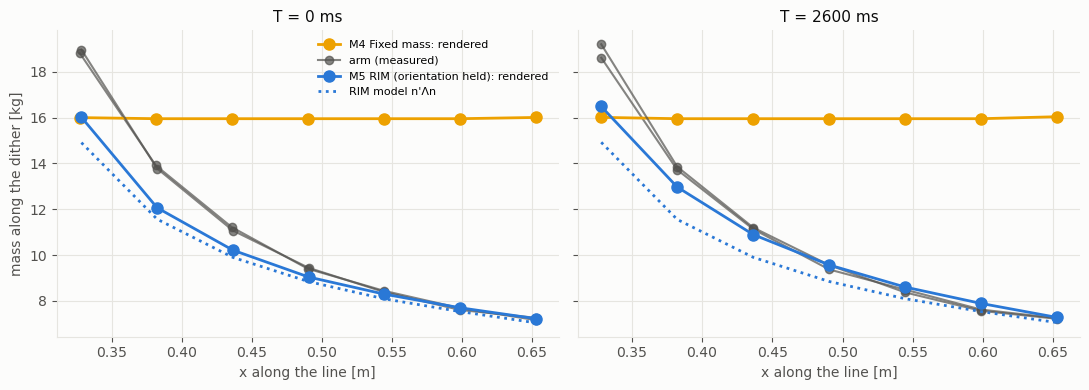

In [6]:
delays = [d for d in P.DELAYS if d in set(df.rtt.map(P.delay_key))]
fig, axes = plt.subplots(1, len(delays), figsize=(5.5 * len(delays), 4), sharey=True, squeeze=False)
for ax, T in zip(axes[0], delays):
    for _, row in df[df.rtt.map(P.delay_key) == T].iterrows():
        rows = [r for r in res[row.dir]["mass_by_s"] if r is not None]
        origin = np.asarray(loaded[row.dir]["meta"]["leader_origin"], float)
        xs = [origin[0] + r["s_m"] for r in rows]
        ax.plot(
            xs,
            [r["m_robot"] for r in rows],
            "o-",
            lw=1.5,
            ms=6,
            color=P.INK_2,
            alpha=0.7,
            label="arm (measured)" if row.method == "proxy-rim" else None,
        )
        ax.plot(
            xs,
            [r["m_felt"] for r in rows],
            "o-",
            lw=2,
            ms=8,
            color=P.color(row.method),
            label=f"{P.LABELS.get(row.method, row.method)}: rendered",
        )
        if row.method == "proxy-rim":
            ax.plot(xs, [r.get("m_model") for r in rows], ":", lw=2, color=P.color(row.method), label="RIM model n'Λn")
    ax.set(title=f"T = {T if T == '5g' else T + ' ms'}", xlabel="x along the line [m]")
axes[0, 0].set_ylabel("mass along the dither [kg]")
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()

## Mass error and tracking along the line

Left: the mass the operator was not shown, $m_{err}$ (solid T = 0, dashed T = 2.6 s): M4's should grow away from
its tuning point, M5's should stay small (or a constant fraction, with E1's unmodelled inertia). Right: robot /
proxy amplitude at the dither frequency — near 1 the robot tracks the proxy, and $m_{err} \approx m_{robot} - m_{felt}$.

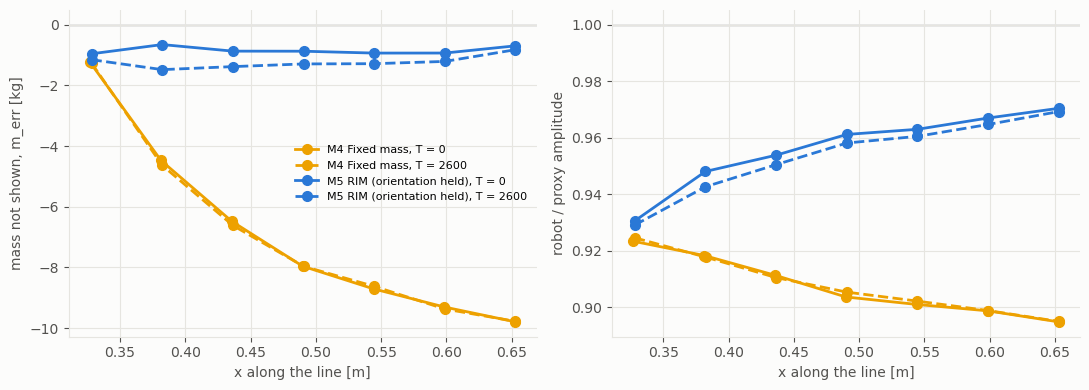

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for _, row in df.iterrows():
    rows = [r for r in res[row.dir]["mass_by_s"] if r is not None]
    origin = np.asarray(loaded[row.dir]["meta"]["leader_origin"], float)
    xs = [origin[0] + r["s_m"] for r in rows]
    ls = "-" if P.delay_key(row.rtt) == "0" else "--"
    lab = f"{P.LABELS.get(row.method, row.method)}, T = {P.delay_key(row.rtt)}"
    axes[0].plot(xs, [r["m_err"] for r in rows], "o" + ls, lw=2, ms=7, color=P.color(row.method), label=lab)
    axes[1].plot(xs, [r["tracking"] for r in rows], "o" + ls, lw=2, ms=7, color=P.color(row.method), label=lab)
axes[0].axhline(0, color="0.6", lw=1, zorder=0)
axes[1].axhline(1, color="0.6", lw=1, zorder=0)
axes[0].set(xlabel="x along the line [m]", ylabel="mass not shown, m_err [kg]")
axes[1].set(xlabel="x along the line [m]", ylabel="robot / proxy amplitude")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()

## e_F and Λ along the line

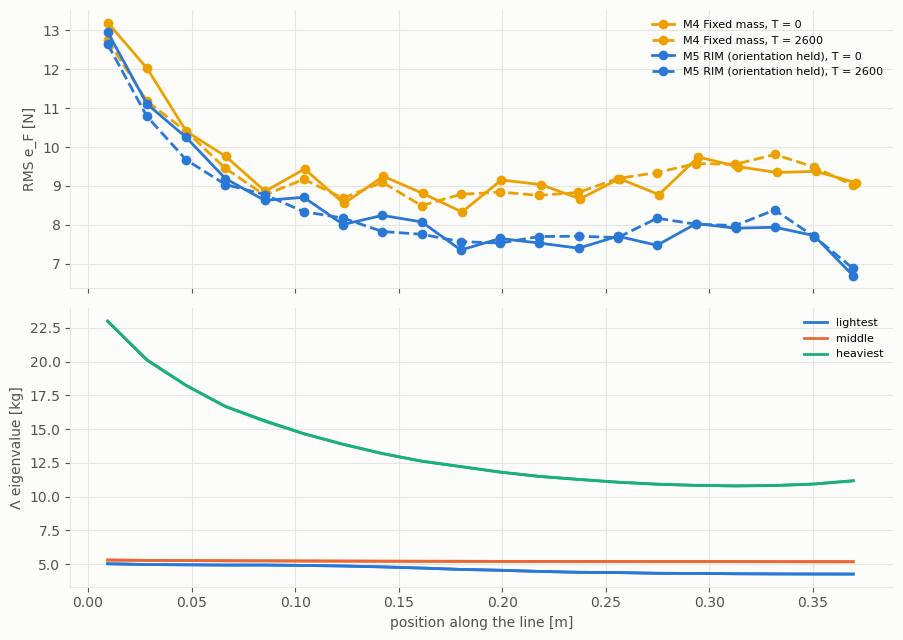

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for _, row in df.iterrows():
    m = P.metrics_of(row.dir)
    y = np.array([np.nan if v is None else v for v in m["eF_rms_by_s"]])
    axes[0].plot(
        m["s_m"],
        y,
        marker="o",
        color=P.color(row.method),
        ls="-" if P.delay_key(row.rtt) == "0" else "--",
        label=f"{P.LABELS.get(row.method, row.method)}, T = {P.delay_key(row.rtt)}",
    )
    if "lambda_eig_by_s" in m:
        eig = np.array([[np.nan] * 3 if v is None else v for v in m["lambda_eig_by_s"]])
        for k, name in enumerate(("lightest", "middle", "heaviest")):
            axes[1].plot(m["s_m"], eig[:, k], color=["#2a78d6", "#eb6834", "#1baf7a"][k], label=name)
axes[0].set_ylabel("RMS e_F [N]")
axes[1].set_ylabel("Λ eigenvalue [kg]")
axes[1].set_xlabel("position along the line [m]")
axes[0].legend(fontsize=8)
handles, labels = axes[1].get_legend_handles_labels()
unique = dict(zip(labels, handles))  # one entry per eigenvalue, not per run
axes[1].legend(unique.values(), unique.keys(), fontsize=8)
fig.tight_layout()

## Discussion (`zdither`, 2026-10-26, 4 runs)

- **M4 is right only where it was tuned; M5 follows the arm.** The arm's measured mass along z falls ×2.6 along the
  line (18.8 → 7.2 kg from x = 0.33 to 0.65 m). M4 renders a flat 15.95 kg: the mass the operator is not shown goes
  from −1.2 kg at its tuning point to −9.8 kg at full reach. M5 renders its model (16.0 → 7.2 kg, model 14.9 → 7.0)
  and its error stays at −0.7 to −1.5 kg along the whole line. Mass-error RMS: M4 7.4 kg, M5 0.85–1.24 kg.
- **Flat in the delay:** T = 0 and 2.6 s agree within ~0.5 kg everywhere.
- **The robot tracks the proxy** (89–97 % of its amplitude at 0.7 Hz), so the comparison is on the same motion — the
  first design's failure mode (44–66 %, on the coupling resonance) is gone.
- **e_F RMS alone does not show it** (M4 10.3 N, M5 9.3 N): friction (Coulomb ~10 N near the base, ~3.5 N at full
  reach) dominates the RMS. The phase separation is what isolates the inertia.

**Unmodelled dynamics.** The arm is heavier than the model near the base (18.8 vs 14.9 kg, ×1.26) and matches it at
full reach (7.2 vs 7.0 kg, ×1.03): the excess inertia depends on the configuration, as reflected rotor inertia
would, but a uniform armature does not fit its size everywhere (0.10 kg·m² fits mid-line, E1's 0.25 overshoots at
full reach) — per-joint values would be needed. Left out of the model on purpose. M5's error stays small despite the
excess near the base partly because the robot there tracks only ~93 % of the proxy.


## The first design (x at z = 0.25 m, 1 cm at 1.5 Hz along the line) — why it was replaced

Set `DESIGN = ""` to see it. All four runs were valid (M4 13.41 kg, T = 0 and 2.6 s), but they could not separate
M4 from M5: the 1.5 Hz dither sat on the proxy's coupling resonance ($\sqrt{K/m}/2\pi$ = 1.37 Hz for 13.4 kg,
~1.6 Hz for M5's ~10 kg), so the proxy swung ±15–17 mm for the leader's ±10 mm and the robot followed only 44–66 %
of it, 6–20° late — $e_F$ measured that tracking shortfall and ~11–16 N of friction. And Λ along x hardly changes on
that line (12.7 → 9.5 → 10.9 kg). What it did show: both methods render as designed (M4 13.3 kg everywhere, M5
following the model, flat in the delay), and the arm's measured mass along x fell from ~15–18 kg near the base to
~6–9 kg at full reach — far more than the held model's ±15 % (the orientation hold relatively softer as the arm
extends, at 1.5 Hz: a hypothesis, the frequency dependence M6 targets).